<a href="https://colab.research.google.com/github/fergonzalvo/ISSD_PH/blob/main/Procesamiento_de_Archivos_PDF_%F0%9F%93%9C%F0%9F%92%BB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pymupdf

In [2]:
# @title
from IPython.display import HTML, display

html_code = """
<style>
@import url('https://fonts.googleapis.com/css2?family=Plus+Jakarta+Sans:wght@500;700;800&display=swap');

.banner-pdf {
    position: relative;
    background: linear-gradient(145deg, #13111c 0%, #221a36 100%);
    border-radius: 12px;
    padding: 30px 40px;
    margin: 20px auto;
    max-width: 900px;
    overflow: hidden;
    box-shadow:
        0 15px 35px rgba(0,0,0,0.6),
        inset 0 1px 0 rgba(255,255,255,0.08),
        inset 0 -1px 0 rgba(0,0,0,0.5);
    display: flex;
    flex-direction: column;
    justify-content: center;
    transform-style: preserve-3d;
    perspective: 1000px;
}

.banner-pdf::before {
    content: '';
    position: absolute;
    left: 0;
    top: 0;
    width: 6px;
    height: 100%;
    background: linear-gradient(180deg, #7c3aed, #a78bfa, #7c3aed);
    background-size: 100% 200%;
    animation: neonFlow 3s linear infinite;
    box-shadow: 5px 0 15px rgba(167, 139, 250, 0.4);
}

.banner-pdf::after {
    content: '';
    position: absolute;
    right: -10%;
    top: -50%;
    width: 220px;
    height: 220px;
    background: radial-gradient(circle, rgba(167, 139, 250, 0.15) 0%, transparent 65%);
    border-radius: 50%;
    animation: pulseGlow 4s ease-in-out infinite alternate;
    pointer-events: none;
}

/* Contenedor principal del texto */
.title-wrapper {
    width: 100%;
    overflow: hidden;
    white-space: nowrap;
    transform-style: preserve-3d;
    display: flex;
}

/* Bloque que contiene ambos textos para el bucle fluido */
.scroll-container {
    display: inline-flex;
    white-space: nowrap;
    animation: scrollContinuous 16s linear infinite;
}

.title-pdf {
    font-family: 'Plus Jakarta Sans', sans-serif;
    font-size: 34px;
    font-weight: 800;
    margin: 0;
    padding-right: 50px;
    color: #e2e8f0;
    text-shadow:
        1px 1px 0px rgba(0,0,0,0.8),
        0px 0px 12px rgba(167, 139, 250, 0.5);
    letter-spacing: 0.5px;
}

.title-pdf span {
    color: #a78bfa;
}

.subtitle-pdf {
    font-family: 'Plus Jakarta Sans', sans-serif;
    color: #94a3b8;
    font-size: 13px;
    letter-spacing: 2px;
    font-weight: 600;
    margin-top: 15px;
    text-transform: uppercase;
    transform: translateZ(10px);
}

@keyframes scrollContinuous {
    0% {
        transform: translateX(0%) translateZ(20px);
    }
    100% {
        transform: translateX(-50%) translateZ(20px);
    }
}

@keyframes neonFlow {
    0% { background-position: 0% 0%; }
    100% { background-position: 0% 200%; }
}

@keyframes pulseGlow {
    0% { transform: scale(1); opacity: 0.5; }
    100% { transform: scale(1.3); opacity: 0.85; }
}
</style>

<div class="banner-pdf">
    <div class="title-wrapper">
        <div class="scroll-container">
            <h1 class="title-pdf">📄📑 <span>TP: Procesamiento de PDF</span> - Extracción de Datos y Análisis de Documentos - 🔍⚙️ //</h1>
            <h1 class="title-pdf">📄📑 <span>TP: Procesamiento de PDF</span> - Extracción de Datos y Análisis de Documentos - 🔍⚙️ //</h1>
        </div>
    </div>
    <p class="subtitle-pdf">Fernando Gonzalvo</p>
</div>
"""

display(HTML(html_code))

#1. Adquisición y metadatos

In [3]:


import requests
import fitz  # libreria para trabajar con pdf PyMuPDF


url = "https://catedras.facet.unt.edu.ar/intar/wp-content/uploads/sites/31/2018/04/4.1-Redes-Neuronales_2018.pdf"#PDF con su enlace público aprobado
nombre_archivo = "redes_neuronales_cerebro.pdf"
response = requests.get(url)
response.raise_for_status()  # Verifica que la descarga haya sido exitosa

with open(nombre_archivo, "wb") as f:
    f.write(response.content)
print(f"archivo '{nombre_archivo}' descargado correctamente")

doc = fitz.open(nombre_archivo)
metadatos = doc.metadata #extracción de metadatos utilizando PyMuPDF (fitz)


print("Metadatos:")
print(f"Título: {metadatos.get('title', 'No disponible')}")
print(f"Autor: {metadatos.get('author', 'No disponible')}")
print(f"Número de páginas: {len(doc)}")
print(f"Software de creación (Producer/Creator): {metadatos.get('producer', metadatos.get('creator', 'No disponible'))}")

doc.close()#necesario para eliminar ram y cerrar dependencias.

archivo 'redes_neuronales_cerebro.pdf' descargado correctamente
Metadatos:
Título: 4.1 - Redes Neuronales.key
Autor: 
Número de páginas: 35
Software de creación (Producer/Creator): Mac OS X 10.13.3 Quartz PDFContext


##Conclusiones:

###el campo "Título del documento:" nos muestra "valor 4.1 - Redes Neuronales.key". Esto significa que el archivo originalmente fue hecho con KeyNote, el programa de notas de Apple, como una presentación de diapositivas, y después exportado a PDF, podriamos esperar capturas erroneas por incompatibilidad
###el campo "Autor" se encuentra vacío, los metadatos no fueron agregados.
###El documento cuenta con 35 páginas y su software de creación indica haber sido generado con Mac OS X 10.13.3 Quartz PDFContext, que, como mencionabamos,puede generar alteraciones estructurales entre plataformas.

#2. Análisis estructural del texto

In [4]:
doc = fitz.open("redes_neuronales_cerebro.pdf")#abrimos el documento con PyMuPDF


pagina_idx =3 # Índice 3 corresponde a la página 4
pagina = doc[pagina_idx]#seleccion de pagina al azar para extraer texto


texto_crudo = pagina.get_text("text")#función para la extracción cruda del texto

print(f"extraccion en crudo (Página {pagina_idx + 1})")
print(texto_crudo[:600])  # mostramos 600 caracteres para analizarlos


print("¿Contiene saltos de línea (\\n)?:", "\n" in texto_crudo)# Verificamos la presencia de saltos de línea y espacios múltiples
print("¿Contiene tabulaciones (\\t)?:", "\t" in texto_crudo)
bloques = pagina.get_text("blocks")#.get_text entiende el parametro "blocks" devuelve un tupla con la ubicación
print(f"Total de bloques de texto estructural detectados: {len(bloques)}\n")#myPuPDF usa cuadrantes.

for i, b in enumerate(bloques[:3]):#ia generativa
    print(f"--- Bloque {i+1} ---")
    print(f"Coordenadas (x0, y0, x1, y1): {b[:4]}")
    print(f"Contenido:\n{repr(b[4])}\n")

texto_crudo = pagina.get_text("text")
print("--- Conteo de caracteres separadores en la página ---")
print(f"Saltos de línea (\\n): {texto_crudo.count(chr(10))}")
print(f"Tabulaciones (\\t): {texto_crudo.count(chr(9))}")


doc.close()

extraccion en crudo (Página 4)
L a c o r t e z a c e r e b r a l d e l c e r e b r o 
humano contiene aproximadamente 15.000 a 
100.000 millones de neuronas dependiendo 
del género y la edad. 
Cada una de las cuales se encuentra 
i n t e r c o n e c t a d a s h a s t a c o n 1 0 . 0 0 0 
conexiones sinápticas.  
Cada milímetro cúbico de córtex cerebral 
contiene aproximadamente 1.000 millones de 
sinapsis. 
INTRODUCCIÓN - CEREBRO HUMANO  

¿Contiene saltos de línea (\n)?: True
¿Contiene tabulaciones (\t)?: False
Total de bloques de texto estructural detectados: 11

--- Bloque 1 ---
Coordenadas (x0, y0, x1, y1): (23.0, 116.0, 434.761962890625, 139.44000244140625)
Contenido:
'L a c o r t e z a c e r e b r a l d e l c e r e b r o \n'

--- Bloque 2 ---
Coordenadas (x0, y0, x1, y1): (23.0, 150.0, 434.8659362792969, 173.44000244140625)
Contenido:
'humano contiene aproximadamente 15.000 a \n'

--- Bloque 3 ---
Coordenadas (x0, y0, x1, y1): (23.0, 185.0, 434.8680725097656, 208.44000244140625)


##Conclusiones:

###como era de esperarse, por posible incompatibilidad de plataformas, o por, posiblemente, un interlineado al centro, la primera oración queda con un error estructural cuando la extraemos en crudo. realizamos comprobaciones de saltos de pagina y tabulaciones y usamos la funcion ".get_text("blocks")" que devuelve una tupla con la ubicación del cuadrante, contamos cuantos bloques hay y mostramos los 3 primeros. debajo dejamos un grafico con la distribucion de los cuadrantes que hace la libreria PyMUPDF , que no siguen una distribución normal.


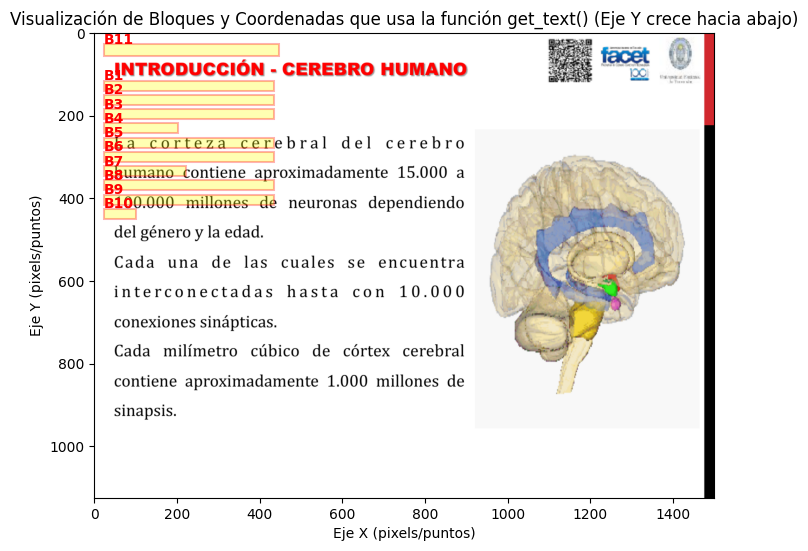

In [5]:
# @title
# ==========================================
# Visualización gráfica de bloques y coordenadas
# ==========================================

import fitz
import matplotlib.pyplot as plt

# Abrir el documento y seleccionar la página 4 (índice 3)
doc = fitz.open("redes_neuronales_cerebro.pdf")
pagina = doc[3]

# Extraer la imagen de la página para usarla como fondo del gráfico
pix = pagina.get_pixmap(dpi=150)
imagen_path = "pagina_4.png"
pix.save(imagen_path)

# Configurar el gráfico con matplotlib
fig, ax = plt.subplots(figsize=(8, 10))
img = plt.imread(imagen_path)
ax.imshow(img)

# Obtener los bloques de texto
bloques = pagina.get_text("blocks")

# Dibujar las "cajas" (bounding boxes) de cada bloque detectado
for i, b in enumerate(bloques):
    x0, y0, x1, y1, texto, block_no, block_type = b
    # Escalamos las coordenadas si es necesario, PyMuPDF ya las da en puntos de la página
    ancho = x1 - x0
    alto = y1 - y0

    # Crear un rectángulo en el gráfico
    rect = plt.Rectangle((x0, y0), ancho, alto, linewidth=1.5, edgecolor='red', facecolor='yellow', alpha=0.3)
    ax.add_patch(rect)

    # Etiquetar el número de bloque
    ax.text(x0, y0 - 2, f"B{i+1}", color='red', fontsize=10, weight='bold')

plt.title("Visualización de Bloques y Coordenadas que usa la función get_text() (Eje Y crece hacia abajo)", fontsize=12)
plt.xlabel("Eje X (pixels/puntos)")
plt.ylabel("Eje Y (pixels/puntos)")
plt.show()

doc.close()

#3: Extracción de datos tabulares

In [6]:
!pip install -q pdfplumber #celda de instalación
import pdfplumber

In [7]:


import pandas as pd

archivo_pdf = "redes_neuronales_cerebro.pdf"
pagina_objetivo = 20  # apuntamos a la página 20

with pdfplumber.open(archivo_pdf) as pdf:
    pagina = pdf.pages[pagina_objetivo - 1]
    tablas = pagina.extract_tables()

    if tablas:
        print(f"¡Éxito! Se encontró una tabla automática en la página {pagina_objetivo}.\n")
        tabla_datos = tablas[0]

        # Convertimos la tabla extraída en un DataFrame de Pandas
        encabezados = tabla_datos[0]
        filas = tabla_datos[1:]

        df = pd.DataFrame(filas, columns=encabezados)

        # Limpieza básica requerida por la cátedra:
        df = df.dropna(how='all')  # Eliminar filas completamente vacías
        df.columns = [str(col).strip() if col else f"Columna_{i}" for i, col in enumerate(df.columns)]

        print("=== DATAFRAME OBTENIDO Y LIMPIO AUTOMÁTICAMENTE ===")
        display(df)
    else:
        print(f"No se detectaron tablas automáticas en la página {pagina_objetivo}.")

¡Éxito! Se encontró una tabla automática en la página 20.

=== DATAFRAME OBTENIDO Y LIMPIO AUTOMÁTICAMENTE ===


,"COMPARATIVA DE LA IA TRADICIONAL Y\nLAS REDES NEURONALES ARTIFICIALES (ANS)\nInteligencia Artificial Redes Neuronales\nEnfoque Descendente Enfoque Ascendente\nBasado en la Psicologia Basado en la Biologia\nQue hace el Cerebro Como lo hace el Cerebro\nReglas tipo Si/Entonces Generalización a Partir de Ejemplos\nSistemas Programados Sistemas Entrenados\nLogica, Conceptos, Reglas Reconocimiento de patrones\nArquitectura Von Neumann, Arquitectura Paralela, Distribuida,\nSeparación Hardware/Software Adaptativa, Autoorganización\nhttp://www.ibm.com/smarterplanet/us/en/ibmwatson/what-is-watson.html",Columna_1
0,None,


##Conclusiones:

###podemos observar que la captura de la tabla por parte de plumberPfd no fue correcta,en este pdf, generado a partir de Keynote. las tablas, no suelen tener trazadas las líneas de grilla reales en el pdf. algo necesario para poder identificarlas.


##Solución:
###recurrimos al método .extract_words() que nos permite obtener las palabras con cada uno de sus cuadrantes para poder generar la grilla correspondiente. vamos generar el codigo con ia generativa y a aplicarlo a esta grilla y obtener la tabla comparativa

In [8]:
with pdfplumber.open(archivo_pdf) as pdf:
    pagina = pdf.pages[pagina_objetivo - 1]

    # Extraemos todas las palabras con sus coordenadas espaciales
    palabras = pagina.extract_words()

    # Definimos el punto medio horizontal para dividir la tabla en dos columnas
    # (En una diapositiva típica, la mitad ronda los 300-350 puntos)
    punto_medio_x = 330

    # Filtramos palabras para la columna izquierda y derecha
    izq_palabras = [p for p in palabras if p['x0'] < punto_medio_x]
    der_palabras = [p for p in palabras if p['x0'] >= punto_medio_x]

    # Función para agrupar palabras que pertenecen a la misma línea vertical
    def agrupar_por_linea(lista_palabras):
        lineas = {}
        for p in lista_palabras:
            y_aprox = round(p['top'] / 12) * 12  # Tolerancia vertical para la misma línea
            if y_aprox not in lineas:
                lineas[y_aprox] = []
            lineas[y_aprox].append(p['text'])
        return [" ".join(palabras_linea) for _, palabras_linea in sorted(lineas.items())]

    columna_ia = agrupar_por_linea(izq_palabras)
    columna_rn = agrupar_por_linea(der_palabras)

    # Normalizamos el tamaño de las listas para que tengan la misma cantidad de filas
    max_len = max(len(columna_ia), len(columna_rn))
    columna_ia += [""] * (max_len - len(columna_ia))
    columna_rn += [""] * (max_len - len(columna_rn))

    # Creamos el DataFrame de Pandas
    df_tabla = pd.DataFrame({
        "Inteligencia Artificial": columna_ia,
        "Redes Neuronales": columna_rn
    })

    # Limpieza básica requerida por la cátedra
    df_tabla = df_tabla.dropna(how='all')

    print("=== DATAFRAME DE LA COMPARATIVA (PÁGINA 20) ===")
    display(df_tabla)

=== DATAFRAME DE LA COMPARATIVA (PÁGINA 20) ===


,Inteligencia Artificial,Redes Neuronales
0,COMPARATIVA DE LA IA TRADICIONAL,Y
1,LAS REDES NEURONALES ARTIFICIALES,(ANS)
2,Inteligencia Artificial,Redes Neuronales
3,Enfoque Descendente,Enfoque Ascendente
4,Basado en la Psicologia,Basado en la Biologia
5,Que hace el Cerebro,Como lo hace el Cerebro
6,Reglas tipo Si/Entonces Generalización,a Partir de Ejemplos
7,Sistemas Programados,Sistemas Entrenados
8,"Logica, Conceptos, Reglas",Reconocimiento de patrones
9,"Arquitectura Von Neumann, Arquitectura","Paralela, Distribuida,"


#4. Análisis de frecuencias (NLP básico)

In [9]:
import fitz  # PyMuPDF
import nltk
from nltk.tokenize import word_tokenize
nltk.download('punkt_tab', quiet=True)

True

In [10]:
archivo_pdf = "redes_neuronales_cerebro.pdf"
pagina_objetivo = 23  # página con texto elegido


doc = fitz.open(archivo_pdf)#abrimos archivo
pagina = doc[pagina_objetivo - 1]#el indice empieza en 0
texto_narrativo = pagina.get_text("text")#extraemos todo el texto crudo
doc.close()#cerramos el documento


texto_minusculas = texto_narrativo.lower()# funcion lower para minusculas


tokens = word_tokenize(texto_minusculas, language='spanish')#funcion de nltk exclusiva para tokenizar

#imprimimos todo
print(f"=== TEXTO ORIGINAL (Primeros 300 caracteres) ===")
print(texto_narrativo[:300])

print(f"\n=== RESULTADO DE LA TOKENIZACIÓN ===")
print(f"Total de tokens generados: {len(tokens)}")
print(f"Primeros 30 tokens en minúsculas:\n{tokens[:30]}")

=== TEXTO ORIGINAL (Primeros 300 caracteres) ===
“Las redes neuronales artificiales son redes interconectadas masivamente en 
paralelo y con organización jerárquica, las cuales intentan interactuar con los 
objetos del mundo real del mismo modo que lo hace el sistema nervioso 
biológico”. (Teuvo Kohonen) 
“Modelos matematicos desarrollados para em

=== RESULTADO DE LA TOKENIZACIÓN ===
Total de tokens generados: 59
Primeros 30 tokens en minúsculas:
['“', 'las', 'redes', 'neuronales', 'artificiales', 'son', 'redes', 'interconectadas', 'masivamente', 'en', 'paralelo', 'y', 'con', 'organización', 'jerárquica', ',', 'las', 'cuales', 'intentan', 'interactuar', 'con', 'los', 'objetos', 'del', 'mundo', 'real', 'del', 'mismo', 'modo', 'que']


In [11]:
import string
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)


# Cargamos las stop words en español y los signos de puntuación
stop_words_es = set(stopwords.words('spanish'))

comillas_extras = {'"', "''", '``', '“', '”', '‘', '’', '«', '»', '—', '–'}
signos_puntuacion = set(string.punctuation).union(comillas_extras)


tokens_limpios = [
    token for token in tokens
    if token not in stop_words_es
    and token not in signos_puntuacion
    and not token.isdigit()  # filtramos números aislados
]

print(f"=== RESULTADO DE LA LIMPIEZA ===")
print(f"Total de tokens iniciales: {len(tokens)}")
print(f"Total de tokens limpios: {len(tokens_limpios)}")
print(f"\nPrimeros 30 tokens ya limpios:\n{tokens_limpios[:30]}")

=== RESULTADO DE LA LIMPIEZA ===
Total de tokens iniciales: 59
Total de tokens limpios: 34

Primeros 30 tokens ya limpios:
['redes', 'neuronales', 'artificiales', 'redes', 'interconectadas', 'masivamente', 'paralelo', 'organización', 'jerárquica', 'cuales', 'intentan', 'interactuar', 'objetos', 'mundo', 'real', 'mismo', 'modo', 'hace', 'sistema', 'nervioso', 'biológico', 'teuvo', 'kohonen', 'modelos', 'matematicos', 'desarrollados', 'emular', 'cerebro', 'humano', 'chen-1998']


15 DE PALABRAS MÁS FRECUENTES
- redes: 3 veces
- neuronales: 2 veces
- artificiales: 2 veces
- interconectadas: 1 veces
- masivamente: 1 veces
- paralelo: 1 veces
- organización: 1 veces
- jerárquica: 1 veces
- cuales: 1 veces
- intentan: 1 veces
- interactuar: 1 veces
- objetos: 1 veces
- mundo: 1 veces
- real: 1 veces
- mismo: 1 veces


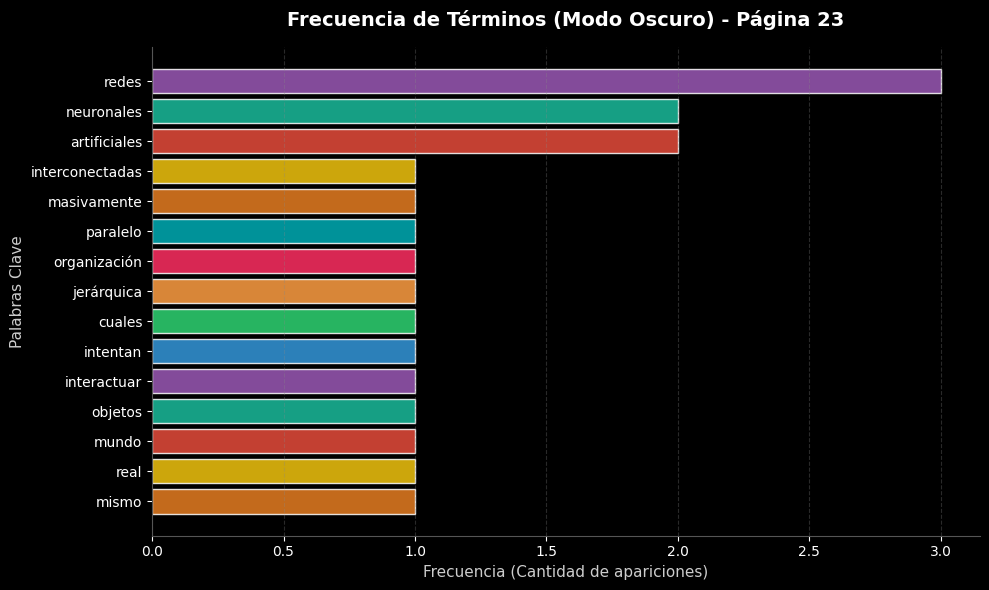

In [12]:
import matplotlib.pyplot as plt
from nltk.probability import FreqDist

fdist = FreqDist(tokens_limpios)
comunes = fdist.most_common(15)


palabras, frecuencias = zip(*comunes)#metodo especial para separar una lista tuplas en dos listas independientes.

print("15 DE PALABRAS MÁS FRECUENTES")
for palabra, frecuencia in fdist.most_common(15):#con un for , mostramos las 15 palabras mas frecuentes
    print(f"- {palabra}: {frecuencia} veces")


plt.style.use('dark_background')#Modo Oscuro para Matplotlib
fig, ax = plt.subplots(figsize=(10, 6))#full ia generativa para obtener el grafico deseado


colores = ['#00adb5', '#ff2e63', '#ff9f43', '#2ed573', '#3498db',
           '#9b59b6', '#1abc9c', '#e74c3c', '#f1c40f', '#e67e22']


barras = ax.barh(palabras[::-1], frecuencias[::-1], color=colores[::-1], edgecolor='white', alpha=0.85)


ax.set_title("Frecuencia de Términos (Modo Oscuro) - Página 23", fontsize=14, color='white', pad=15, weight='bold')
ax.set_xlabel("Frecuencia (Cantidad de apariciones)", fontsize=11, color='#cccccc')
ax.set_ylabel("Palabras Clave", fontsize=11, color='#cccccc')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#555555')
ax.spines['bottom'].set_color('#555555')
ax.grid(axis='x', linestyle='--', alpha=0.3, color='#888888')

plt.tight_layout()
plt.show()

##Conclusiones:

###se obtuvieron las 15 palabras mas frecuentes y se generó un grafico con matplotlib que las agrupa, mostrando su frecuencia. como era de esperar en este texto, la palabras redes, es la que mas figura en la pagina, por la naturaleza del texto elegido.